# SIT720 6.1 Pass Task - Linear Regression and Logistic Regression

**Student:** Zenith Anthony  
**Student ID:** s225534396  
**Dataset:** UCI Machine Learning Repository - Automobile (205 records)  
**Targets:** `price` for regression and `LuxuryCar` for binary classification.

This notebook implements Part B of the task using reproducible preprocessing pipelines, feature selection, model evaluation, and regularisation. The random seed is fixed to 42 so the results are repeatable.

In [1]:
# Core libraries
from pathlib import Path
import subprocess, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression
from sklearn.feature_selection import SelectKBest, f_regression, f_classif
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, roc_auc_score
)

warnings.filterwarnings('ignore', message='Found unknown categories*')
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', message='Inconsistent values:*')
pd.set_option('display.max_columns', 60)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
RANDOM_STATE = 42

## 1. Data preparation and encoding

The official UCI dataset contains missing values. The code first uses a local cached copy when available (for reproducible execution in this submission environment). Otherwise it fetches dataset ID 10 from UCI using `ucimlrepo`. Column names are normalised by replacing hyphens with underscores.

In [2]:
# Load the UCI Automobile dataset
local_candidates = [
    Path('/mnt/data/automobiles_uci_equiv.csv'),
    Path('automobiles_uci_equiv.csv'),
    Path('automobile.csv')
]
local_file = next((p for p in local_candidates if p.exists()), None)

if local_file is not None:
    df = pd.read_csv(local_file)
    data_source = f'Local cached UCI copy: {local_file}'
else:
    try:
        from ucimlrepo import fetch_ucirepo
    except ImportError:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'ucimlrepo'])
        from ucimlrepo import fetch_ucirepo
    automobile = fetch_ucirepo(id=10)
    if hasattr(automobile.data, 'original') and automobile.data.original is not None:
        df = automobile.data.original.copy()
    else:
        df = pd.concat([automobile.data.features, automobile.data.targets], axis=1)
    data_source = 'UCI Machine Learning Repository via ucimlrepo (dataset id=10)'

# Standardise column names and convert UCI ? markers to missing values.
df.columns = [str(c).strip().lower().replace('-', '_') for c in df.columns]
df = df.replace('?', np.nan)

# Convert known numeric columns to numeric (invalid strings become NaN).
numeric_expected = [
    'symboling','normalized_losses','wheel_base','length','width','height','curb_weight',
    'engine_size','bore','stroke','compression_ratio','horsepower','peak_rpm',
    'city_mpg','highway_mpg','price'
]
for c in numeric_expected:
    if c in df.columns:
        df[c] = pd.to_numeric(df[c], errors='coerce')

print(data_source)
print('Dataset shape:', df.shape)
display(df.head())

Local cached UCI copy: /mnt/data/automobiles_uci_equiv.csv
Dataset shape: (205, 26)


,symboling,normalized_losses,make,fuel_type,aspiration,num_of_doors,body_style,drive_wheels,engine_location,wheel_base,length,width,height,curb_weight,engine_type,num_of_cylinders,engine_size,fuel_system,bore,stroke,compression_ratio,horsepower,peak_rpm,city_mpg,highway_mpg,price
0,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6000,168.8000,64.1000,48.8000,2548,dohc,four,130,mpfi,3.4700,2.6800,9.0000,111.0000,"5,000.0000",21,27,"13,495.0000"
1,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6000,168.8000,64.1000,48.8000,2548,dohc,four,130,mpfi,3.4700,2.6800,9.0000,111.0000,"5,000.0000",21,27,"16,500.0000"
2,1,NaN,alfa-romero,gas,std,two,hatchback,rwd,front,94.5000,171.2000,65.5000,52.4000,2823,ohcv,six,152,mpfi,2.6800,3.4700,9.0000,154.0000,"5,000.0000",19,26,"16,500.0000"
3,2,164.0000,audi,gas,std,four,sedan,fwd,front,99.8000,176.6000,66.2000,54.3000,2337,ohc,four,109,mpfi,3.1900,3.4000,10.0000,102.0000,"5,500.0000",24,30,"13,950.0000"
4,2,164.0000,audi,gas,std,four,sedan,4wd,front,99.4000,176.6000,66.4000,54.3000,2824,ohc,five,136,mpfi,3.1900,3.4000,8.0000,115.0000,"5,500.0000",18,22,"17,450.0000"


Data types:


,dtype
symboling,int64
normalized_losses,float64
make,object
fuel_type,object
aspiration,object
num_of_doors,object
body_style,object
drive_wheels,object
engine_location,object
wheel_base,float64


Features with missing values:


,missing_count
normalized_losses,41
stroke,4
price,4
bore,4
horsepower,2
peak_rpm,2
num_of_doors,2


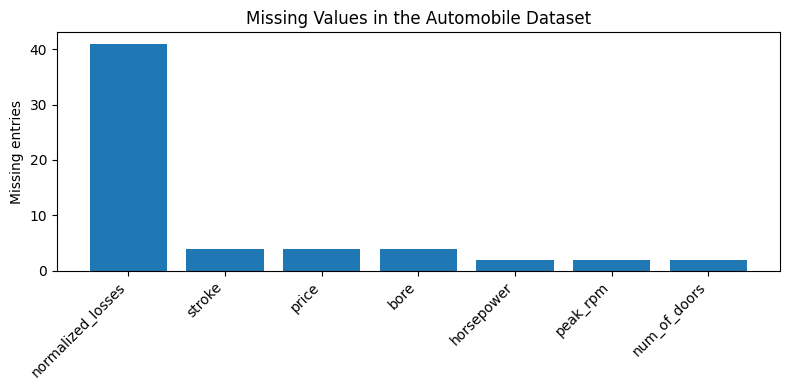

In [3]:
# Inspect feature types and missing values
print('Data types:')
display(df.dtypes.to_frame('dtype'))

missing = df.isna().sum().sort_values(ascending=False)
missing = missing[missing > 0].to_frame('missing_count')
print('Features with missing values:')
display(missing)

plt.figure(figsize=(8, 4))
plt.bar(missing.index, missing['missing_count'])
plt.title('Missing Values in the Automobile Dataset')
plt.ylabel('Missing entries')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

### Preprocessing decisions

- Rows with missing `price` are removed because the supervised regression target cannot be imputed without inventing labels.
- The assignment defines `LuxuryCar = 1` when price is greater than the median price, otherwise 0.
- Numeric predictors are median-imputed and standardised. Median imputation is robust to skew and outliers; scaling is important for coefficient comparison and regularisation.
- Categorical predictors are mode-imputed and one-hot encoded. One reference level is dropped to reduce redundant dummy variables.
- One stratified 80/20 split is used for both tasks so the same vehicles form the training and test sets, while the luxury classes remain balanced.

In [4]:
# Remove records with unknown supervised target and create LuxuryCar
model_df = df.dropna(subset=['price']).copy()
median_price = model_df['price'].median()
model_df['LuxuryCar'] = (model_df['price'] > median_price).astype(int)

print(f'Rows after dropping missing price: {len(model_df)}')
print(f'Median vehicle price: ${median_price:,.2f}')
print('LuxuryCar class counts:')
display(model_df['LuxuryCar'].value_counts().sort_index().rename(index={0:'Non-luxury (0)', 1:'Luxury (1)'}).to_frame('count'))

X = model_df.drop(columns=['price', 'LuxuryCar'])
y_reg = model_df['price']
y_cls = model_df['LuxuryCar']

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = [c for c in X.columns if c not in numeric_features]

feature_types = pd.DataFrame({
    'feature': X.columns,
    'type': ['continuous/numeric' if c in numeric_features else 'categorical' for c in X.columns]
})
display(feature_types)

indices = np.arange(len(model_df))
train_idx, test_idx = train_test_split(
    indices, test_size=0.20, random_state=RANDOM_STATE, stratify=y_cls
)
X_train, X_test = X.iloc[train_idx].copy(), X.iloc[test_idx].copy()
y_reg_train, y_reg_test = y_reg.iloc[train_idx], y_reg.iloc[test_idx]
y_cls_train, y_cls_test = y_cls.iloc[train_idx], y_cls.iloc[test_idx]

print('Train/test sizes:', X_train.shape, X_test.shape)
print('Training class counts:', y_cls_train.value_counts().sort_index().to_dict())
print('Test class counts:', y_cls_test.value_counts().sort_index().to_dict())

Rows after dropping missing price: 201
Median vehicle price: $10,295.00
LuxuryCar class counts:


,count
LuxuryCar,
Non-luxury (0),101
Luxury (1),100


,feature,type
0,symboling,continuous/numeric
1,normalized_losses,continuous/numeric
2,make,categorical
3,fuel_type,categorical
4,aspiration,categorical
5,num_of_doors,categorical
6,body_style,categorical
7,drive_wheels,categorical
8,engine_location,categorical
9,wheel_base,continuous/numeric


Train/test sizes: (160, 25) (41, 25)
Training class counts: {0: 80, 1: 80}
Test class counts: {0: 21, 1: 20}


In [5]:
# Shared preprocessing pipeline
numeric_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', drop='first', sparse_output=False))
])

preprocessor = ColumnTransformer([
    ('num', numeric_pipe, numeric_features),
    ('cat', categorical_pipe, categorical_features)
])

print('Numeric features:', len(numeric_features))
print('Categorical features:', len(categorical_features))

Numeric features: 15
Categorical features: 10


## 2. Linear Regression - vehicle price prediction

In [6]:
def regression_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {
        'MAE': mean_absolute_error(y_true, y_pred),
        'MSE': mse,
        'RMSE': np.sqrt(mse),
        'R2': r2_score(y_true, y_pred)
    }

linear_model = Pipeline([
    ('preprocess', preprocessor),
    ('model', LinearRegression())
])
linear_model.fit(X_train, y_reg_train)

lin_train_pred = linear_model.predict(X_train)
lin_test_pred = linear_model.predict(X_test)

linear_metrics = pd.DataFrame([
    {'Set':'Train', **regression_metrics(y_reg_train, lin_train_pred)},
    {'Set':'Test', **regression_metrics(y_reg_test, lin_test_pred)}
]).set_index('Set')
print('Linear Regression performance:')
display(linear_metrics)
print(f"Intercept: {linear_model.named_steps['model'].intercept_:,.2f}")

Linear Regression performance:


,MAE,MSE,RMSE,R2
Set,,,,
Train,802.4567,"1,314,389.6668","1,146.4683",0.9777
Test,"3,335.3025","19,861,469.6745","4,456.6209",0.7383


Intercept: 24,625.75


Largest coefficients overall (categorical coefficients are relative to a reference category):


,feature,coefficient,abs_coefficient
24,cat__make_mercury,"-12,210.5512","12,210.5512"
44,cat__engine_location_rear,"10,656.6172","10,656.6172"
25,cat__make_mitsubishi,"-10,475.6853","10,475.6853"
18,cat__make_dodge,"-10,233.4883","10,233.4883"
28,cat__make_plymouth,"-9,891.0574","9,891.0574"
50,cat__num_of_cylinders_five,"-9,669.1030","9,669.1030"
34,cat__make_volvo,"-9,449.1016","9,449.1016"
32,cat__make_toyota,"-8,383.7297","8,383.7297"
54,cat__num_of_cylinders_twelve,"-7,998.2075","7,998.2075"
19,cat__make_honda,"-7,818.9755","7,818.9755"


Most influential standardised numeric predictors:


,feature,coefficient,abs_coefficient
6,num__curb_weight,"3,514.7395","3,514.7395"
7,num__engine_size,"2,511.8284","2,511.8284"
3,num__length,"-2,049.1433","2,049.1433"
4,num__width,"1,740.8406","1,740.8406"
11,num__horsepower,"1,493.6333","1,493.6333"
10,num__compression_ratio,"-1,462.5098","1,462.5098"
2,num__wheel_base,"1,214.1253","1,214.1253"
12,num__peak_rpm,929.1964,929.1964
9,num__stroke,-915.8103,915.8103
5,num__height,-877.7255,877.7255


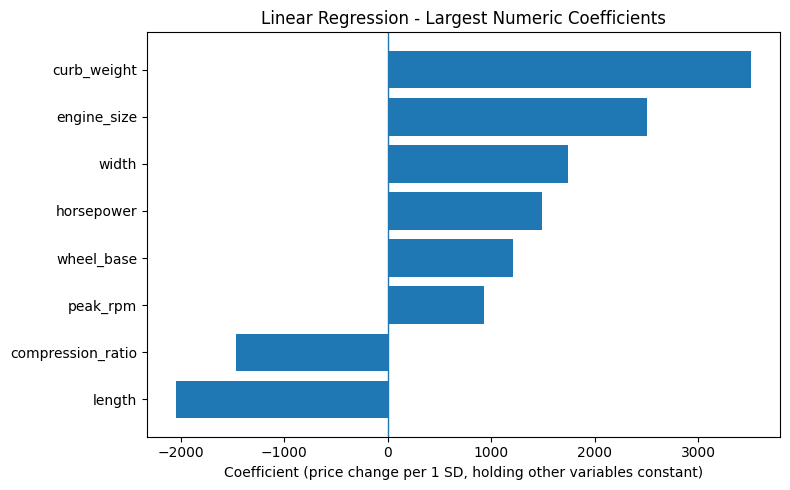

In [7]:
# Learned coefficients
feature_names = linear_model.named_steps['preprocess'].get_feature_names_out()
linear_coefs = pd.DataFrame({
    'feature': feature_names,
    'coefficient': linear_model.named_steps['model'].coef_
})
linear_coefs['abs_coefficient'] = linear_coefs['coefficient'].abs()

print('Largest coefficients overall (categorical coefficients are relative to a reference category):')
display(linear_coefs.sort_values('abs_coefficient', ascending=False).head(15))

numeric_coef_table = linear_coefs[linear_coefs['feature'].str.startswith('num__')].copy()
numeric_coef_table = numeric_coef_table.sort_values('abs_coefficient', ascending=False)
print('Most influential standardised numeric predictors:')
display(numeric_coef_table.head(10))

plt.figure(figsize=(8, 5))
top_num = numeric_coef_table.head(8).sort_values('coefficient')
plt.barh(top_num['feature'].str.replace('num__','', regex=False), top_num['coefficient'])
plt.axvline(0, linewidth=1)
plt.title('Linear Regression - Largest Numeric Coefficients')
plt.xlabel('Coefficient (price change per 1 SD, holding other variables constant)')
plt.tight_layout()
plt.show()

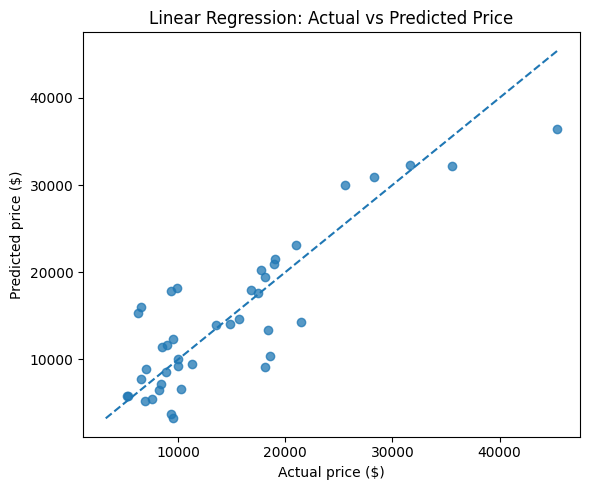

In [8]:
# Actual versus predicted price
plt.figure(figsize=(6, 5))
plt.scatter(y_reg_test, lin_test_pred, alpha=0.75)
lo = min(y_reg_test.min(), lin_test_pred.min())
hi = max(y_reg_test.max(), lin_test_pred.max())
plt.plot([lo, hi], [lo, hi], linestyle='--')
plt.xlabel('Actual price ($)')
plt.ylabel('Predicted price ($)')
plt.title('Linear Regression: Actual vs Predicted Price')
plt.tight_layout()
plt.show()

## 3. Evaluating Linear Regression

MAE measures the typical absolute dollar error. MSE squares errors and therefore penalises large misses strongly. RMSE is the square root of MSE and returns the error to dollars. R² measures the proportion of price variance explained by the model. The train/test gap is also used to judge generalisation.

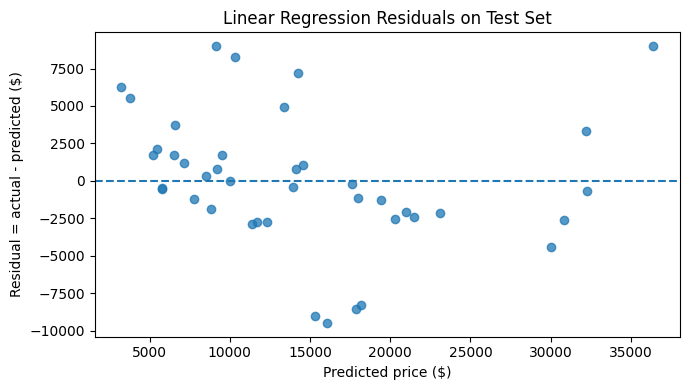

Largest absolute test errors:


,actual,predicted,absolute_error
5,"6,575.0000","16,066.2968","9,491.2968"
18,"6,295.0000","15,316.3286","9,021.3286"
6,"18,150.0000","9,154.5642","8,995.4358"
2,"45,400.0000","36,408.6654","8,991.3346"
37,"9,295.0000","17,887.1011","8,592.1011"
21,"9,895.0000","18,180.4426","8,285.4426"
17,"18,620.0000","10,356.1121","8,263.8879"
13,"21,485.0000","14,268.4034","7,216.5966"
16,"9,538.0000","3,242.4390","6,295.5610"
34,"9,298.0000","3,751.2991","5,546.7009"


In [9]:
# Residual inspection
residuals = y_reg_test - lin_test_pred
plt.figure(figsize=(7, 4))
plt.scatter(lin_test_pred, residuals, alpha=0.75)
plt.axhline(0, linestyle='--')
plt.xlabel('Predicted price ($)')
plt.ylabel('Residual = actual - predicted ($)')
plt.title('Linear Regression Residuals on Test Set')
plt.tight_layout()
plt.show()

print('Largest absolute test errors:')
err_table = pd.DataFrame({
    'actual': y_reg_test.to_numpy(),
    'predicted': lin_test_pred,
    'absolute_error': np.abs(y_reg_test.to_numpy() - lin_test_pred)
}).sort_values('absolute_error', ascending=False)
display(err_table.head(10))

## 4. Logistic Regression - LuxuryCar classification

In [10]:
def classification_metrics(y_true, y_pred, y_prob):
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred),
        'Recall': recall_score(y_true, y_pred),
        'F1': f1_score(y_true, y_pred),
        'AUC': roc_auc_score(y_true, y_prob)
    }

# No penalty is used here so Q7 can compare explicit L1/L2 regularisation with a non-regularised baseline.
logistic_model = Pipeline([
    ('preprocess', preprocessor),
    ('model', LogisticRegression(penalty=None, solver='lbfgs', max_iter=5000))
])
logistic_model.fit(X_train, y_cls_train)

log_train_pred = logistic_model.predict(X_train)
log_test_pred = logistic_model.predict(X_test)
log_train_prob = logistic_model.predict_proba(X_train)[:, 1]
log_test_prob = logistic_model.predict_proba(X_test)[:, 1]

logistic_metrics = pd.DataFrame([
    {'Set':'Train', **classification_metrics(y_cls_train, log_train_pred, log_train_prob)},
    {'Set':'Test', **classification_metrics(y_cls_test, log_test_pred, log_test_prob)}
]).set_index('Set')
print('Unregularised Logistic Regression performance:')
display(logistic_metrics)

prediction_examples = pd.DataFrame({
    'Actual': y_cls_test.to_numpy(),
    'Predicted': log_test_pred,
    'P(LuxuryCar=1)': log_test_prob
})
print('Example predicted labels and probabilities:')
display(prediction_examples.head(15))

Unregularised Logistic Regression performance:


,Accuracy,Precision,Recall,F1,AUC
Set,,,,,
Train,0.9938,1.0000,0.9875,0.9937,0.9999
Test,0.9024,0.8333,1.0000,0.9091,1.0000


Example predicted labels and probabilities:


,Actual,Predicted,P(LuxuryCar=1)
0,0,0,0.0000
1,1,1,1.0000
2,1,1,1.0000
3,0,0,0.0000
4,0,0,0.0000
5,0,0,0.0000
6,1,1,1.0000
7,1,1,1.0000
8,0,0,0.0000
9,1,1,1.0000


Most influential Logistic Regression features:


,feature,coefficient,abs_coefficient
14,num__highway_mpg,-62.6682,62.6682
6,num__curb_weight,57.4888,57.4888
4,num__width,44.0506,44.0506
10,num__compression_ratio,41.8781,41.8781
13,num__city_mpg,-41.5316,41.5316
60,cat__fuel_system_mpfi,37.9730,37.9730
22,cat__make_mazda,35.5382,35.5382
25,cat__make_mitsubishi,-29.4833,29.4833
32,cat__make_toyota,-25.8093,25.8093
41,cat__body_style_wagon,-24.2133,24.2133


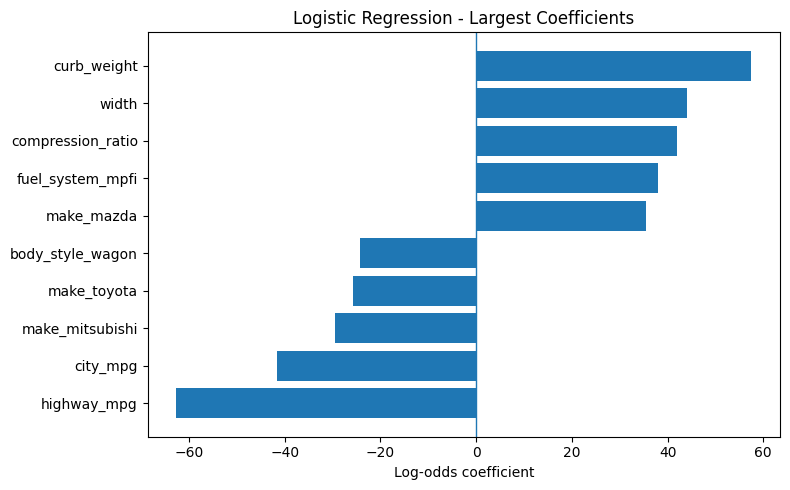

In [11]:
# Logistic Regression coefficients
log_feature_names = logistic_model.named_steps['preprocess'].get_feature_names_out()
log_coefs = pd.DataFrame({
    'feature': log_feature_names,
    'coefficient': logistic_model.named_steps['model'].coef_[0]
})
log_coefs['abs_coefficient'] = log_coefs['coefficient'].abs()
print('Most influential Logistic Regression features:')
display(log_coefs.sort_values('abs_coefficient', ascending=False).head(15))

plt.figure(figsize=(8, 5))
top_log = log_coefs.sort_values('abs_coefficient', ascending=False).head(10).sort_values('coefficient')
plt.barh(top_log['feature'].str.replace('num__','', regex=False).str.replace('cat__','', regex=False), top_log['coefficient'])
plt.axvline(0, linewidth=1)
plt.title('Logistic Regression - Largest Coefficients')
plt.xlabel('Log-odds coefficient')
plt.tight_layout()
plt.show()

## 5. Evaluating Logistic Regression

Confusion matrix:
[[17  4]
 [ 0 20]]


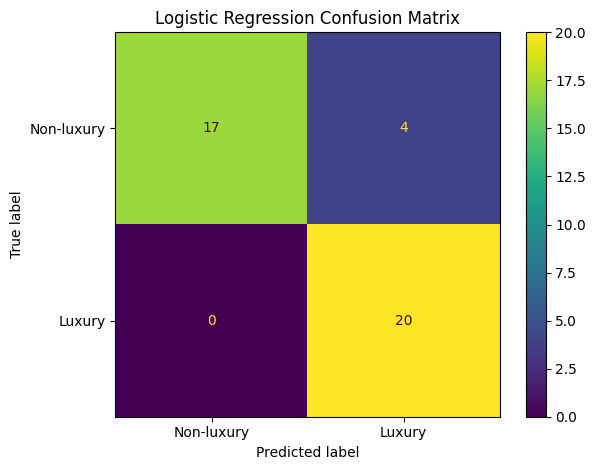

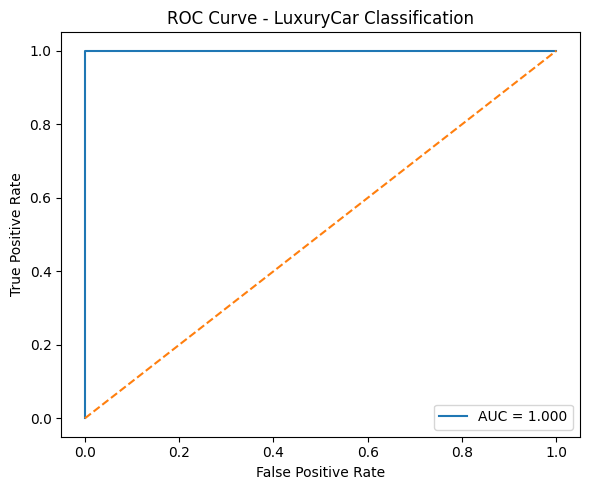

In [12]:
cm = confusion_matrix(y_cls_test, log_test_pred)
print('Confusion matrix:')
print(cm)
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Non-luxury','Luxury']).plot()
plt.title('Logistic Regression Confusion Matrix')
plt.tight_layout()
plt.show()

fpr, tpr, thresholds = roc_curve(y_cls_test, log_test_prob)
auc_value = roc_auc_score(y_cls_test, log_test_prob)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f'AUC = {auc_value:.3f}')
plt.plot([0,1],[0,1], linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - LuxuryCar Classification')
plt.legend()
plt.tight_layout()
plt.show()

## 6. Feature Selection and Model Generalisation

A univariate `SelectKBest` stage is fitted **only on the training data** inside each pipeline. Fifteen transformed features are retained. `f_regression` is used for the continuous price target and `f_classif` for the binary LuxuryCar target.

In [13]:
reg_selected = Pipeline([
    ('preprocess', preprocessor),
    ('select', SelectKBest(score_func=f_regression, k=15)),
    ('model', LinearRegression())
])
reg_selected.fit(X_train, y_reg_train)

reg_selected_metrics = pd.DataFrame([
    {'Set':'Train', **regression_metrics(y_reg_train, reg_selected.predict(X_train))},
    {'Set':'Test', **regression_metrics(y_reg_test, reg_selected.predict(X_test))}
]).set_index('Set')

reg_all_names = reg_selected.named_steps['preprocess'].get_feature_names_out()
reg_selected_names = reg_all_names[reg_selected.named_steps['select'].get_support()]

cls_selected = Pipeline([
    ('preprocess', preprocessor),
    ('select', SelectKBest(score_func=f_classif, k=15)),
    ('model', LogisticRegression(penalty=None, solver='lbfgs', max_iter=5000))
])
cls_selected.fit(X_train, y_cls_train)

cls_sel_train_pred = cls_selected.predict(X_train)
cls_sel_test_pred = cls_selected.predict(X_test)
cls_sel_train_prob = cls_selected.predict_proba(X_train)[:,1]
cls_sel_test_prob = cls_selected.predict_proba(X_test)[:,1]
cls_selected_metrics = pd.DataFrame([
    {'Set':'Train', **classification_metrics(y_cls_train, cls_sel_train_pred, cls_sel_train_prob)},
    {'Set':'Test', **classification_metrics(y_cls_test, cls_sel_test_pred, cls_sel_test_prob)}
]).set_index('Set')

cls_all_names = cls_selected.named_steps['preprocess'].get_feature_names_out()
cls_selected_names = cls_all_names[cls_selected.named_steps['select'].get_support()]

print('Linear Regression with 15 selected features:')
display(reg_selected_metrics)
print('Selected regression features:')
print(list(reg_selected_names))

print('\nLogistic Regression with 15 selected features:')
display(cls_selected_metrics)
print('Selected classification features:')
print(list(cls_selected_names))

Linear Regression with 15 selected features:


,MAE,MSE,RMSE,R2
Set,,,,
Train,"2,183.1028","10,046,802.8502","3,169.6692",0.8293
Test,"1,963.5349","7,355,308.7848","2,712.0673",0.9031


Selected regression features:
['num__wheel_base', 'num__length', 'num__width', 'num__curb_weight', 'num__engine_size', 'num__bore', 'num__horsepower', 'num__city_mpg', 'num__highway_mpg', 'cat__drive_wheels_fwd', 'cat__drive_wheels_rwd', 'cat__num_of_cylinders_four', 'cat__num_of_cylinders_six', 'cat__fuel_system_2bbl', 'cat__fuel_system_mpfi']

Logistic Regression with 15 selected features:


,Accuracy,Precision,Recall,F1,AUC
Set,,,,,
Train,0.9625,0.9744,0.9500,0.9620,0.9932
Test,0.9024,0.8333,1.0000,0.9091,0.9738


Selected classification features:
['num__wheel_base', 'num__length', 'num__width', 'num__curb_weight', 'num__engine_size', 'num__bore', 'num__horsepower', 'num__city_mpg', 'num__highway_mpg', 'cat__drive_wheels_fwd', 'cat__drive_wheels_rwd', 'cat__num_of_cylinders_four', 'cat__num_of_cylinders_six', 'cat__fuel_system_2bbl', 'cat__fuel_system_mpfi']


In [14]:
# Compact generalisation comparison
feature_selection_summary = pd.DataFrame({
    'Model': ['Linear - all', 'Linear - selected 15', 'Logistic - all', 'Logistic - selected 15'],
    'Train score': [
        linear_metrics.loc['Train','R2'], reg_selected_metrics.loc['Train','R2'],
        logistic_metrics.loc['Train','Accuracy'], cls_selected_metrics.loc['Train','Accuracy']
    ],
    'Test score': [
        linear_metrics.loc['Test','R2'], reg_selected_metrics.loc['Test','R2'],
        logistic_metrics.loc['Test','Accuracy'], cls_selected_metrics.loc['Test','Accuracy']
    ],
    'Score type': ['R2','R2','Accuracy','Accuracy']
})
display(feature_selection_summary)

,Model,Train score,Test score,Score type
0,Linear - all,0.9777,0.7383,R2
1,Linear - selected 15,0.8293,0.9031,R2
2,Logistic - all,0.9938,0.9024,Accuracy
3,Logistic - selected 15,0.9625,0.9024,Accuracy


## 7. Regularisation for improving model performance

Ridge applies an L2 penalty that shrinks coefficients smoothly, while Lasso applies an L1 penalty that can shrink some coefficients to exactly zero. For Logistic Regression, L1 and L2 penalties are compared with the unregularised baseline. Hyperparameters are chosen using 5-fold cross-validation on the training set only.

In [15]:
# Ridge and Lasso tuning for regression
alphas = [0.01, 0.1, 1, 10, 100]
reg_results = []
reg_models = {}

for name, estimator in [
    ('Ridge', Ridge()),
    ('Lasso', Lasso(max_iter=50000))
]:
    pipe = Pipeline([
        ('preprocess', preprocessor),
        ('model', estimator)
    ])
    search = GridSearchCV(
        pipe, {'model__alpha': alphas}, cv=5,
        scoring='neg_root_mean_squared_error', n_jobs=1
    )
    search.fit(X_train, y_reg_train)
    reg_models[name] = search.best_estimator_
    tr = regression_metrics(y_reg_train, search.predict(X_train))
    te = regression_metrics(y_reg_test, search.predict(X_test))
    reg_results.append({
        'Model': name,
        'Best alpha': search.best_params_['model__alpha'],
        'CV RMSE': -search.best_score_,
        'Train RMSE': tr['RMSE'], 'Test RMSE': te['RMSE'],
        'Train R2': tr['R2'], 'Test R2': te['R2']
    })

reg_regularisation = pd.DataFrame(reg_results).set_index('Model')
print('Regularised regression results:')
display(reg_regularisation)

Regularised regression results:


,Best alpha,CV RMSE,Train RMSE,Test RMSE,Train R2,Test R2
Model,,,,,,
Ridge,0.1000,"2,491.6230","1,207.8824","3,321.5279",0.9752,0.8546
Lasso,10.0000,"2,641.1535","1,420.8921","2,855.4039",0.9657,0.8926


In [16]:
# L1 and L2 tuning for Logistic Regression
C_values = [0.01, 0.1, 1, 10, 100]
log_reg_results = []
log_reg_models = {}

for penalty in ['l1', 'l2']:
    pipe = Pipeline([
        ('preprocess', preprocessor),
        ('model', LogisticRegression(penalty=penalty, solver='liblinear', max_iter=5000))
    ])
    search = GridSearchCV(pipe, {'model__C': C_values}, cv=5, scoring='roc_auc', n_jobs=1)
    search.fit(X_train, y_cls_train)
    log_reg_models[penalty] = search.best_estimator_
    tr_pred = search.predict(X_train)
    te_pred = search.predict(X_test)
    tr_prob = search.predict_proba(X_train)[:,1]
    te_prob = search.predict_proba(X_test)[:,1]
    tr = classification_metrics(y_cls_train, tr_pred, tr_prob)
    te = classification_metrics(y_cls_test, te_pred, te_prob)
    log_reg_results.append({
        'Penalty': penalty.upper(),
        'Best C': search.best_params_['model__C'],
        'CV AUC': search.best_score_,
        'Train Accuracy': tr['Accuracy'], 'Test Accuracy': te['Accuracy'],
        'Test Precision': te['Precision'], 'Test Recall': te['Recall'],
        'Test F1': te['F1'], 'Test AUC': te['AUC']
    })

log_regularisation = pd.DataFrame(log_reg_results).set_index('Penalty')
print('Regularised Logistic Regression results:')
display(log_regularisation)

print('Baseline unregularised Logistic Regression test metrics:')
display(logistic_metrics.loc[['Test']])

Regularised Logistic Regression results:


,Best C,CV AUC,Train Accuracy,Test Accuracy,Test Precision,Test Recall,Test F1,Test AUC
Penalty,,,,,,,,
L1,1,0.9750,0.9437,0.9268,0.9048,0.9500,0.9268,0.9881
L2,1,0.9797,0.9500,0.9268,0.9048,0.9500,0.9268,0.9905


Baseline unregularised Logistic Regression test metrics:


,Accuracy,Precision,Recall,F1,AUC
Set,,,,,
Test,0.9024,0.8333,1.0000,0.9091,1.0000


,Model,Test R2,Test RMSE
0,Linear,0.7383,"4,456.6209"
1,Ridge,0.8546,"3,321.5279"
2,Lasso,0.8926,"2,855.4039"


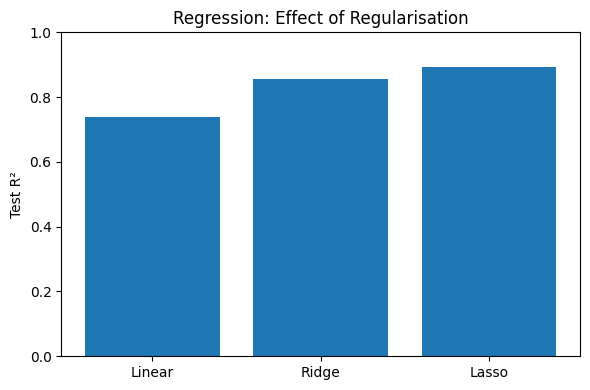

,Model,Test Accuracy,Test AUC
0,Unregularised,0.9024,1.0000
1,L1,0.9268,0.9881
2,L2,0.9268,0.9905


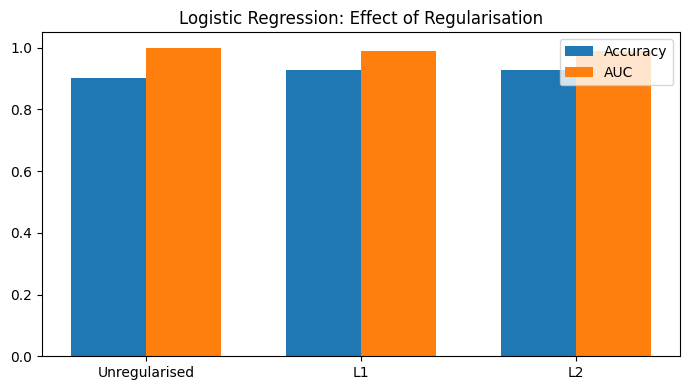

In [17]:
# Model comparison figures
reg_compare = pd.DataFrame({
    'Model': ['Linear', 'Ridge', 'Lasso'],
    'Test R2': [linear_metrics.loc['Test','R2'], reg_regularisation.loc['Ridge','Test R2'], reg_regularisation.loc['Lasso','Test R2']],
    'Test RMSE': [linear_metrics.loc['Test','RMSE'], reg_regularisation.loc['Ridge','Test RMSE'], reg_regularisation.loc['Lasso','Test RMSE']]
})
display(reg_compare)

plt.figure(figsize=(6,4))
plt.bar(reg_compare['Model'], reg_compare['Test R2'])
plt.ylabel('Test R²')
plt.title('Regression: Effect of Regularisation')
plt.ylim(0,1)
plt.tight_layout()
plt.show()

log_compare = pd.DataFrame({
    'Model': ['Unregularised', 'L1', 'L2'],
    'Test Accuracy': [logistic_metrics.loc['Test','Accuracy'], log_regularisation.loc['L1','Test Accuracy'], log_regularisation.loc['L2','Test Accuracy']],
    'Test AUC': [logistic_metrics.loc['Test','AUC'], log_regularisation.loc['L1','Test AUC'], log_regularisation.loc['L2','Test AUC']]
})
display(log_compare)

x = np.arange(len(log_compare))
width = 0.35
plt.figure(figsize=(7,4))
plt.bar(x-width/2, log_compare['Test Accuracy'], width, label='Accuracy')
plt.bar(x+width/2, log_compare['Test AUC'], width, label='AUC')
plt.xticks(x, log_compare['Model'])
plt.ylim(0,1.05)
plt.title('Logistic Regression: Effect of Regularisation')
plt.legend()
plt.tight_layout()
plt.show()

## Key findings

- The full Linear Regression model fits the training data extremely well but generalises less strongly, indicating overfitting from a high-dimensional one-hot encoded feature space and a small dataset.
- Selecting 15 informative transformed features substantially improves test R² and reduces the train-test gap.
- Ridge and Lasso both improve regression generalisation; in this split Lasso gives the better test R² of the two regularised linear models.
- The unregularised Logistic Regression classifier has high recall but produces four false positives. L1 and L2 regularisation improve test accuracy and balance the error pattern.
- Coefficient magnitudes in the unregularised Logistic Regression are very large because the classes are close to linearly separable in this small sample. Regularisation makes the model less extreme and more stable.

## GenAI acknowledgement - edit before submission

ChatGPT was used to assist with planning the analysis, generating initial code scaffolding, and drafting/editing explanatory text. Before submission, the student should personally run and verify the notebook, understand each model and metric, and revise the written explanations in their own words so that the final work accurately reflects their understanding and complies with the assessment instructions.